# Exploratory Data Analysis

Name: Dane Alban

Date: 20Sep2026

## Table of Contents:

- [Exploratory Data Analysis](#exploratory-data-analysis)
- [Data & Details](#data--details)
- [Training Data Info](#training-data-info)
- [Test Data Info](#test-data-info)
- [Target Variable Analysis](#target-variable-analysis)
- [Missing Values Analysis](#missing-values-analysis)
- [Missing Values in Training Data](#missing-values-in-training-data)
- [Missing Values in Test Data](#missing-values-in-test-data)
- [Feature Analysis: Data Types and Unique Values](#feature-analysis-data-types-and-unique-values)
- [Categorical Features](#categorical-features)
- [Numerical Features Summary](#numerical-features-summary)
- [Data Cleaning: Handling "XNA" in "CODE_GENDER"](#data-cleaning-handling-xna-in-code_gender)
- [Exploring Numerical Feature Distributions](#exploring-numerical-feature-distributions)
- [Summary of Exploratory Data Analysis](#summary-of-exploratory-data-analysis)
- [Next Steps](#next-steps)

## Business Problem:

Home Credit currently faces two financially detrimental issues: Rejecting creditworthy
applicants who are fully capable of repayment, and approving loans with unsustainable terms
that lead to default.

## Data & Details:

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Load application_train.csv file:
app_train_df = pd.read_csv('/content/drive/MyDrive/MSBA Practice Project/application_train.csv')

# Load application_test.csv file:
app_test_df = pd.read_csv('/content/drive/MyDrive/MSBA Practice Project/application_test.csv')

# Glimpse into datasets:
display(app_train_df.head())
display(app_test_df.head())
print('Shape of training data:', app_train_df.shape)
print('Shape of test data:', app_test_df.shape)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


Shape of training data: (307511, 122)
Shape of test data: (48744, 121)


### Training Data Info:

In [12]:
app_train_df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Data columns (total 122 columns):
 #    Column                        Non-Null Count   Dtype  
---   ------                        --------------   -----  
 0    SK_ID_CURR                    307511 non-null  int64  
 1    TARGET                        307511 non-null  int64  
 2    NAME_CONTRACT_TYPE            307511 non-null  object 
 3    CODE_GENDER                   307511 non-null  object 
 4    FLAG_OWN_CAR                  307511 non-null  object 
 5    FLAG_OWN_REALTY               307511 non-null  object 
 6    CNT_CHILDREN                  307511 non-null  int64  
 7    AMT_INCOME_TOTAL              307511 non-null  float64
 8    AMT_CREDIT                    307511 non-null  float64
 9    AMT_ANNUITY                   307499 non-null  float64
 10   AMT_GOODS_PRICE               307233 non-null  float64
 11   NAME_TYPE_SUITE               306219 non-null  object 
 12   NAME_INCOME_TYPE            

### Test Data Info:

In [13]:
app_test_df.info(verbose=True, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48744 entries, 0 to 48743
Data columns (total 121 columns):
 #    Column                        Non-Null Count  Dtype  
---   ------                        --------------  -----  
 0    SK_ID_CURR                    48744 non-null  int64  
 1    NAME_CONTRACT_TYPE            48744 non-null  object 
 2    CODE_GENDER                   48744 non-null  object 
 3    FLAG_OWN_CAR                  48744 non-null  object 
 4    FLAG_OWN_REALTY               48744 non-null  object 
 5    CNT_CHILDREN                  48744 non-null  int64  
 6    AMT_INCOME_TOTAL              48744 non-null  float64
 7    AMT_CREDIT                    48744 non-null  float64
 8    AMT_ANNUITY                   48720 non-null  float64
 9    AMT_GOODS_PRICE               48744 non-null  float64
 10   NAME_TYPE_SUITE               47833 non-null  object 
 11   NAME_INCOME_TYPE              48744 non-null  object 
 12   NAME_EDUCATION_TYPE           48744 non-null

## Target Variable Analysis:

Distribution of the target variable:
TARGET
0    282686
1     24825
Name: count, dtype: int64


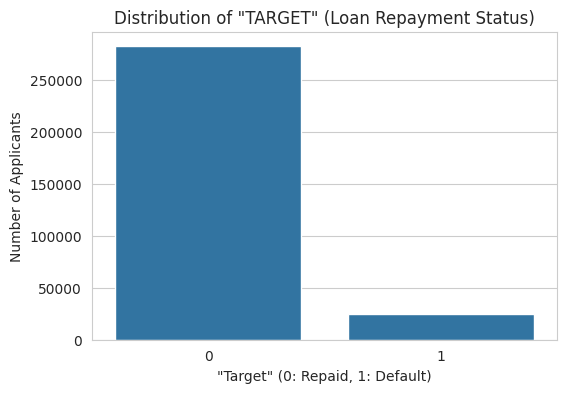

In [24]:
# Count occurrences of each target value:
target_counts = app_train_df['TARGET'].value_counts()

print('Distribution of the target variable:')
print(target_counts)

# Plot the distribution of target variable:
plt.figure(figsize=(6, 4))
sns.barplot(x=target_counts.index, y=target_counts.values)
plt.title('Distribution of "TARGET" (Loan Repayment Status)')
plt.xlabel('"Target" (0: Repaid, 1: Default)')
plt.ylabel('Number of Applicants')
plt.show()

**Comment on the plot above:**
The distribution of the target variable is uneven. Obviously the loan default category should be much smaller than the repayment category, but the large difference betweent them will hav to be considered during trianing so the model doesn't rely on the low overall change of default to base it's predictions on.

## Missing Values Analysis:

In [27]:
# Calculate missing values (by column):
def missing_values_table(df):
    # Total missing values:
    mis_val = df.isnull().sum()

    # Percentage of missing values:
    mis_val_percent = 100 * df.isnull().sum() / len(df)

    # Make table with results:
    mis_val_table = pd.concat([mis_val, mis_val_percent], axis=1)

    # Rename columns:
    mis_val_table_ren_columns = mis_val_table.rename(
    columns = {0 : 'Missing Values', 1 : '% of Total Values'})

    # Sort table by % of missing:
    mis_val_table_ren_columns = mis_val_table_ren_columns[mis_val_table_ren_columns.iloc[:,1] != 0].sort_values(
        '% of Total Values', ascending=False).round(1)

    # Print summary info:
    print ("Your selected dataframe has " + str(df.shape[1]) + " columns.\n"
           "There are " + str(mis_val_table_ren_columns.shape[0]) +
             " columns that have missing values.")

    # Return dataframe with missing information:
    return mis_val_table_ren_columns

### Missing Values in Training Data:

In [16]:
# Missing values in training data:
missing_train = missing_values_table(app_train_df)
display(missing_train.head(20))

Your selected dataframe has 122 columns.
There are 67 columns that have missing values.


,Missing Values,% of Total Values
COMMONAREA_MEDI,214865,69.9
COMMONAREA_MODE,214865,69.9
COMMONAREA_AVG,214865,69.9
NONLIVINGAPARTMENTS_MODE,213514,69.4
NONLIVINGAPARTMENTS_MEDI,213514,69.4
NONLIVINGAPARTMENTS_AVG,213514,69.4
FONDKAPREMONT_MODE,210295,68.4
LIVINGAPARTMENTS_AVG,210199,68.4
LIVINGAPARTMENTS_MEDI,210199,68.4
LIVINGAPARTMENTS_MODE,210199,68.4


### Missing Values in Test Data:

In [17]:
# Missing values in test data:
missing_test = missing_values_table(app_test_df)
display(missing_test.head(20))

Your selected dataframe has 121 columns.
There are 64 columns that have missing values.


,Missing Values,% of Total Values
COMMONAREA_AVG,33495,68.7
COMMONAREA_MODE,33495,68.7
COMMONAREA_MEDI,33495,68.7
NONLIVINGAPARTMENTS_AVG,33347,68.4
NONLIVINGAPARTMENTS_MODE,33347,68.4
NONLIVINGAPARTMENTS_MEDI,33347,68.4
FONDKAPREMONT_MODE,32797,67.3
LIVINGAPARTMENTS_MODE,32780,67.2
LIVINGAPARTMENTS_AVG,32780,67.2
LIVINGAPARTMENTS_MEDI,32780,67.2


**Comment on missing data above:**
Missing data in prediciton models can skew analysis and results because having a lack of indicators provides no useful basis for making predictions, and can over or under weight the data it's associated with on the same rows. This will have to be addressed in cleansing and preparation and/or in the model training.

## Feature Analysis: Data Types and Unique Values

### Categorical Features:

In [29]:
# Select categorical columns
categorical_cols = app_train_df.select_dtypes(include='object').columns

print(f"There are {len(categorical_cols)} categorical features.\n")
print("Unique values for each categorical feature in training data:")
for col in categorical_cols:
    print(f"- {col}: {app_train_df[col].nunique()} unique values")
    # Display unique values if there are not too many
    if app_train_df[col].nunique() < 50:
        display(app_train_df[col].value_counts().sort_index())

There are 16 categorical features.

Unique values for each categorical feature in training data:
- NAME_CONTRACT_TYPE: 2 unique values


,count
NAME_CONTRACT_TYPE,
Cash loans,278232
Revolving loans,29279


- CODE_GENDER: 3 unique values


,count
CODE_GENDER,
F,202448
M,105059
XNA,4


- FLAG_OWN_CAR: 2 unique values


,count
FLAG_OWN_CAR,
N,202924
Y,104587


... (20 outputs left out)

- WALLSMATERIAL_MODE: 7 unique values


,count
WALLSMATERIAL_MODE,
Block,9253
Mixed,2296
Monolithic,1779
Others,1625
Panel,66040
"Stone, brick",64815
Wooden,5362


- EMERGENCYSTATE_MODE: 2 unique values


,count
EMERGENCYSTATE_MODE,
No,159428
Yes,2328


### Numerical Features Summary:

In [19]:
# Select only numerical columns:
numerical_cols = app_train_df.select_dtypes(include=['int64', 'float64']).columns

print(f"There are {len(numerical_cols)} numerical features.\n")
print("Summary statistics for numerical features in training data:")
# Exclude columns "SK_ID_CURR" & "TARGET" from descriptive statistics:
display(app_train_df[numerical_cols.drop(['SK_ID_CURR', 'TARGET'], errors='ignore')].describe().T)

There are 106 numerical features.

Summary statistics for numerical features in training data:


,count,mean,std,min,25%,50%,75%,max
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.5,16524.0,24903.0,34596.0,258025.5
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.0,238500.0,450000.0,679500.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


## Data Cleaning: Handling "XNA" in "CODE_GENDER":

In [30]:
# Replace "XNA" values in "CODE_GENDER" column with NaN:
app_train_df['CODE_GENDER'] = app_train_df['CODE_GENDER'].replace('XNA', np.nan)

print("Updated distribution of CODE_GENDER:")
display(app_train_df['CODE_GENDER'].value_counts(dropna=False))

Updated distribution of CODE_GENDER:


,count
CODE_GENDER,
F,202448
M,105059
NaN,4


## Exploring Numerical Feature Distributions:

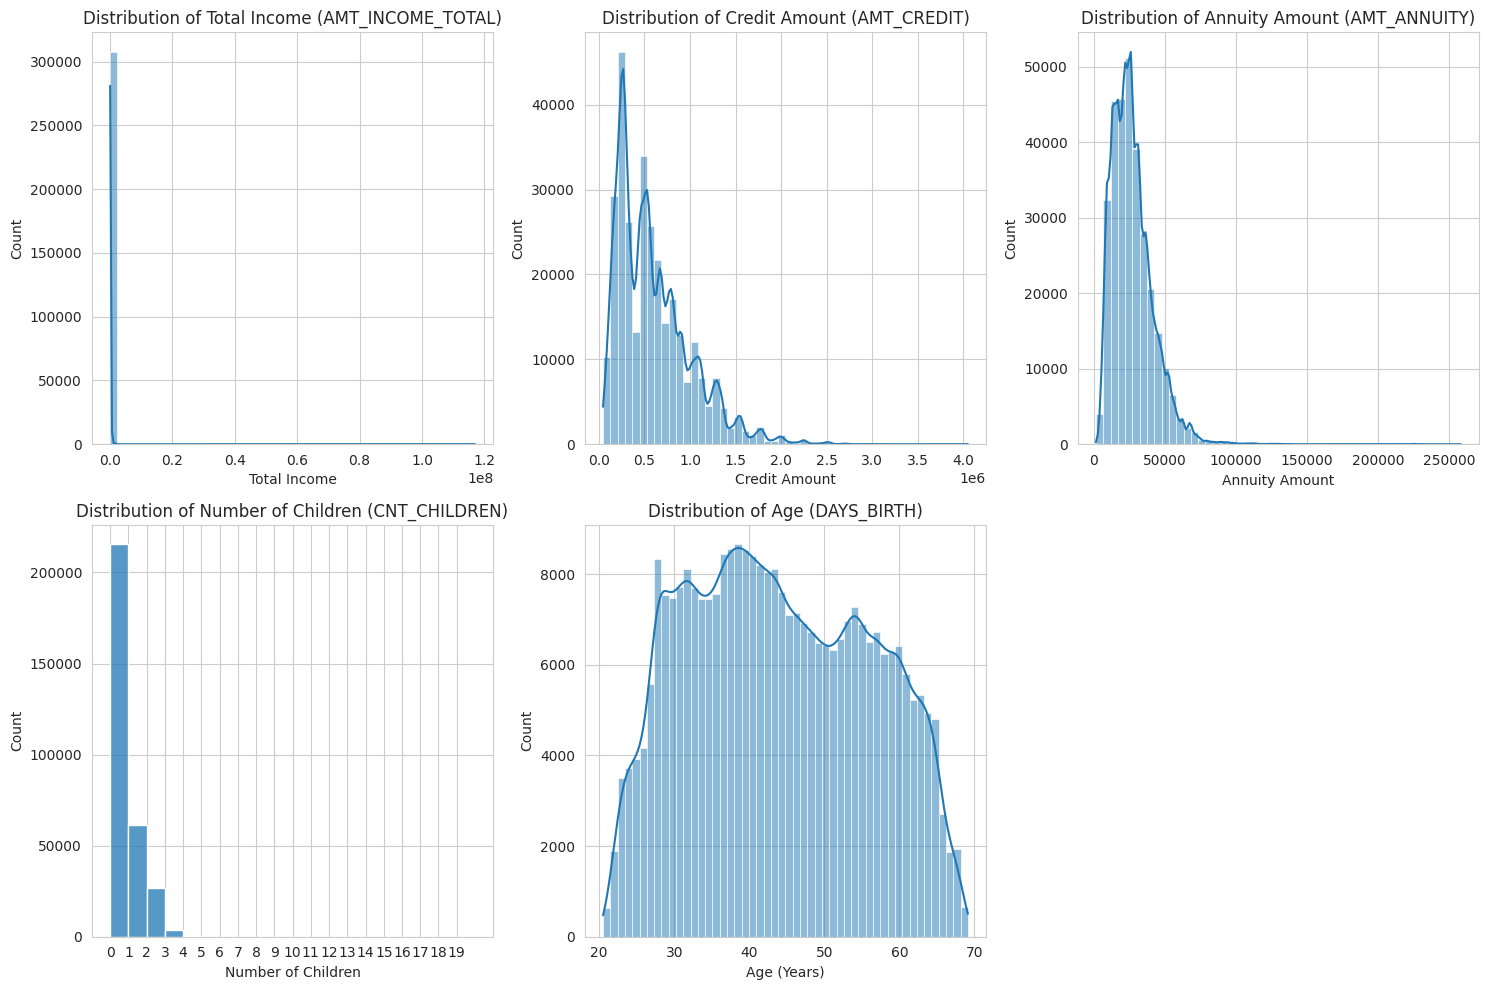

In [21]:
# Set style for plots:
sns.set_style('whitegrid')

# Create a figure and set of subplots:
plt.figure(figsize=(15, 10))

# Plot distribution of "AMT_INCOME_TOTAL":
plt.subplot(2, 3, 1) # 2 rows, 3 columns, 1st plot
sns.histplot(app_train_df['AMT_INCOME_TOTAL'], bins=50, kde=True)
plt.title('Distribution of Total Income (AMT_INCOME_TOTAL)')
plt.xlabel('Total Income')
plt.ylabel('Count')

# Plot distribution of "AMT_CREDIT":
plt.subplot(2, 3, 2) # 2 rows, 3 columns, 2nd plot
sns.histplot(app_train_df['AMT_CREDIT'], bins=50, kde=True)
plt.title('Distribution of Credit Amount (AMT_CREDIT)')
plt.xlabel('Credit Amount')
plt.ylabel('Count')

# Plot distribution of "AMT_ANNUITY":
plt.subplot(2, 3, 3) # 2 rows, 3 columns, 3rd plot
sns.histplot(app_train_df['AMT_ANNUITY'].dropna(), bins=50, kde=True)
plt.title('Distribution of Annuity Amount (AMT_ANNUITY)')
plt.xlabel('Annuity Amount')
plt.ylabel('Count')

# Plot distribution of "CNT_CHILDREN":
plt.subplot(2, 3, 4) # 2 rows, 3 columns, 4th plot
sns.histplot(app_train_df['CNT_CHILDREN'], bins=range(int(app_train_df['CNT_CHILDREN'].max()) + 2), kde=False)
plt.title('Distribution of Number of Children (CNT_CHILDREN)')
plt.xlabel('Number of Children')
plt.ylabel('Count')
plt.xticks(range(int(app_train_df['CNT_CHILDREN'].max()) + 1))

# Plot distribution of "DAYS_BIRTH":
plt.subplot(2, 3, 5) # 2 rows, 3 columns, 5th plot
sns.histplot(app_train_df['DAYS_BIRTH'] / -365, bins=50, kde=True) # Convert to years
plt.title('Distribution of Age (DAYS_BIRTH)')
plt.xlabel('Age (Years)')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

**Comment on the plots above:**
The age, credit, and annuity plots look reasonable. However, the income and age plots appear to have extreme values that are skewing the distribution. The income plot is the most problematic, with most values in the lower ranges while some values in the upper extremes completely tainting the plot and the genreal distribution.

## Summary of Exploratory Data Analysis:

1. Distribution of the target variable (loan repayment or default) is not proportional, with 282,686 rows or 91.93% of the total rows indicating the loan was repaid on time. Only 24,825 rows or 8.07% defaulted. While the lower default number/percentage is good for business (although not as good as it could be), such a disproportionate allocation means care will have to be taken when training the model to it does not favor the majority class.

2. There are missing values in the data (in both the training and test files), with some columns having significant gaps ("COMMONAREA_MEDI" , "NONLIVINGAPARTMENTS_MODE" , "OWN_CAR_AGE") of more than half their data. We will need to decide whether to remove these columns entirely or otherwise handle them carefully during analysis.

3. The "CODE_GENDER" column contained several "XNA" values (representing an unknown gender) which were replaced with not-a-number designations for easier processing.

4. Columns "AMT_INCOME_TOTAL" , "AMT_CREDIT" , and "AMT_ANNUITY" likely contain outliers due to their skewed distribution. These will have to be addressed so they don't taint the analyis. For example:
- "CNT_CHILDREN" contains some extreme values (like 19 children) which are either invalid entries or valid but rare situations.
- "DAYS_EMPLOYED" contains unusual values that need to be addressed.

## Next Steps:

Address missing values and outliers. Understand their context and determine whether they are incorrect entries or rare real-world exampes. Then determine whethe to include them, replace with average values, or remove them entirely. This is required before the model can begin training so it's not affected by incorrect or extraordinary data that will interfere with proper statistical calculations.